# 注意力机制学习笔记

> 参考：《动手学深度学习》第 10 章 注意力机制（https://zh.d2l.ai/chapter_attention-mechanisms/）
> 本笔记随学习进度持续迭代。

---

## 0. 学习进度

- [x] 10.1 注意力提示（Q、K、V 的基本概念）
- [ ] 10.2 注意力汇聚：Nadaraya-Watson 核回归
- [ ] 10.3 注意力评分函数（Softmax、加性注意力、缩放点积注意力）
- [ ] 10.4 Bahdanau 注意力
- [ ] 10.5 多头注意力
- [ ] 10.6 自注意力和位置编码
- [ ] 10.7 Transformer

---

## 1. 注意力机制到底想干什么

**一句话**：从一堆信息里，根据"我当前想找什么"，重点关注相关的部分。

### 图书馆找书的例子

图书馆里有五本书：

| 书名 | 内容 |
| --- | --- |
| Python 编程 | Python 基础语法 |
| 深度学习 | 神经网络与模型训练 |
| 机器学习 | 回归、分类等算法 |
| 中国历史 | 中国历史知识 |
| 高等数学 | 微积分与线性代数 |

心里的需求是：**"我想学习神经网络。"**

你会看每本书的书名，判断它和需求有多相关，最后重点读《深度学习》。

这个过程就是一次注意力机制。

---

## 2. Q、K、V 三个核心概念

### 2.1 Query（Q）：查询

**当前想找什么信息。**

例子中：Q = "我想学习神经网络"

> 实际模型中 Q 不是一句文字，而是表示这句话的一个**向量**。

### 2.2 Key（K）：键

**用来和 Query 比对，判断"这个信息是不是我需要的"。**

例子中每本书的书名就是 Key：

- K₁ = Python 编程
- K₂ = 深度学习
- K₃ = 中国历史

拿 Q 分别和每个 K 匹配：

| Query 与 Key | 相关程度 |
| --- | --- |
| 神经网络 ↔ Python 编程 | 中等 |
| 神经网络 ↔ 深度学习 | 很高 |
| 神经网络 ↔ 中国历史 | 很低 |

> K 的作用：参与匹配，决定对应信息应该得到多少注意力。

### 2.3 Value（V）：值

**真正被提取、汇总的信息。**

书名只能帮你判断是否相关，真正需要的是书里的知识。

- **Key**：书名，负责**匹配**
- **Value**：书中的知识，负责**提供内容**

> **Key 和 Value 一一配对**：K₂ 是《深度学习》，V₂ 就是这本书的内容。
> Q 和 K₂ 最匹配时，V₂ 获得最高的权重。

### 2.4 整体流程示意

```
Query: "我想学习神经网络"
   │
   │  与每个 Key 匹配，计算相关程度
   ▼
┌──────────────┬──────────────┬──────────────┐
│ K: Python编程 │ K: 深度学习   │ K: 中国历史   │
│ V: Python语法 │ V: 神经网络知识│ V: 历史知识   │
│ 权重: 15%     │ 权重: 70%     │ 权重: 15%     │
└──────────────┴──────────────┴──────────────┘
   │
   │  按权重对 Value 加权求和
   ▼
Attention 输出：以神经网络知识为主的信息
```

> 权重是为说明原理编的示例，不是真实模型的计算结果。

---

## 3. 注意力汇聚（Attention Pooling）

### 3.1 计算步骤

以 1 个 Query、5 个 Key-Value 对为例：

1. **Query 进入**注意力汇聚模块，代表当前想获取什么信息
2. **5 个 Key 进入**模块，分别计算 Query 与每个 Key 的匹配程度
3. **得到 5 个注意力权重**，例如：

$$\alpha = [0.05,\ 0.10,\ 0.15,\ 0.20,\ 0.50]$$

   第 5 个 Key 最匹配，所以第 5 个 Value 权重最大

4. **加权求和**：每个权重乘对应的 Value，再相加

$$\text{Output} = 0.05V_1 + 0.10V_2 + 0.15V_3 + 0.20V_4 + 0.50V_5$$

### 3.2 通用公式

$$f(q) = \sum_{i=1}^{n} \alpha(q, k_i)\, v_i$$

- $\alpha(q, k_i)$ 是注意力权重，由 Query 和第 $i$ 个 Key 的匹配程度决定
- 权重满足：每个 $\ge 0$，且总和为 $1$（通常用 Softmax 保证）

> ⚠️ 注意力**不是**只把最匹配的 Value 取出来，而是让它在结果中**占更大比重**，其他 Value 也参与输出。
>
> 可以理解为**"模糊版字典查找"**：普通字典只取完全匹配的那一个；注意力对所有 Value 按匹配度加权平均。

### 3.3 和平均汇聚、全连接层的区别

| 方法 | 权重怎么来 | 和"想找什么"有关吗 |
| --- | --- | --- |
| 平均汇聚 | 全部是 $1/n$ | 无关 |
| 全连接层 / 最大汇聚 | 固定参数或固定规则 | 无关 |
| **注意力汇聚** | 由 Query 和 Key 的匹配**动态算出** | **有关**，Query 变了，关注点就变 |

> 教材原话的意思：**是否引入自主性提示（Query），是注意力机制和全连接层、汇聚层的根本区别。**

---

## 4. 教材术语：自主性提示与非自主性提示

李沐用这两个心理学概念来引出 Q、K、V：

| 教材术语 | 对应 | 例子 |
| --- | --- | --- |
| 自主性提示 | **Query** | 你主动想学习神经网络 |
| 非自主性提示 | **Key** | 《深度学习》这个书名吸引你 |
| 感官输入 | **Value** | 书中的神经网络知识 |

> 这些术语不用过度纠结，理解 Q、K、V 的关系就够了。

---

## 5. 注意力权重的可视化（热图）

有 $m$ 个 Query、$n$ 个 Key 时，所有权重组成一个 **$m \times n$ 矩阵**：

- 每**行**：一个 Query 对所有 Key 的权重分布（每行和为 1）
- 颜色越深：这个 Query 越关注这个 Key



**输入形状（4 维）**：`(子图行数, 子图列数, 查询数, 键数)`

- 前两维：画几行几列子图（以后画多头注意力时用）
- 后两维：每张子图的 $m \times n$ 权重矩阵



In [4]:
import torch
from d2l import torch as d2l

def show_heatmaps(matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5),
                  cmap='Reds'):
    """显示矩阵热图"""
    d2l.use_svg_display()
    num_rows, num_cols = matrices.shape[0], matrices.shape[1]
    fig, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize,
                                 sharex=True, sharey=True, squeeze=False)
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6);

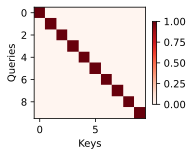

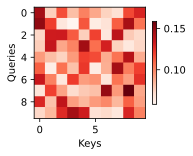

In [8]:
attention_weights = torch.eye(10).reshape((1, 1, 10, 10)) # 一行一列就是一张热力图
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')
scores = torch.rand(10,10)
weights = torch.softmax(scores, dim=-1)
show_heatmaps(weights.reshape((1,1,10,10)), xlabel='Keys', ylabel='Queries')

### 带注意力机制的Seq2Seq   
![截屏2026-11-12 02.53.14.png](<attachment:截屏2026-11-12 02.53.14.png>)
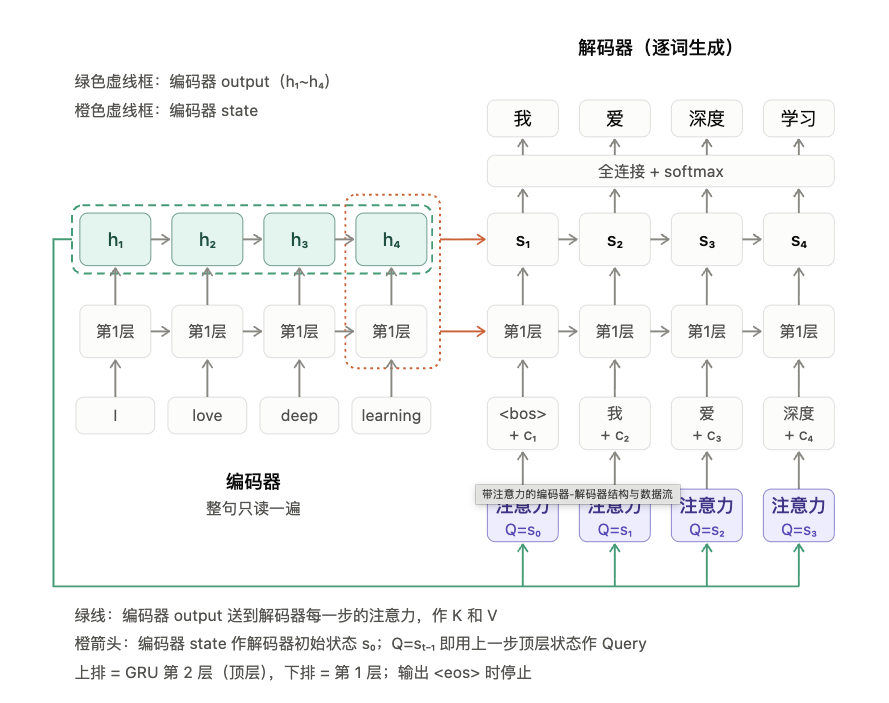

## 注意力汇聚：Nadaraya-Watson 核回归


In [9]:
import torch
from torch import nn
from d2l import torch as d2l

### 制造数据
**问题**：给定数据集 $\{(x_1, y_1), \ldots, (x_n, y_n)\}$，学习 $f$，预测新输入 $x$ 的输出 $\hat{y} = f(x)$。

**人工数据集**（$\epsilon$ 为噪声）：

$$y_i = 2\sin(x_i) + x_i^{0.8} + \epsilon$$

In [ ]:
n_train = 50  # 训练样本数
x_train, _ = torch.sort(torch.rand(n_train) * 5)   # 排序后的训练样本

def f(x):
    return 2 * torch.sin(x) + x**0.8

y_train = f(x_train) + torch.normal(0.0, 0.5, (n_train,))  # 训练样本的输出：f+噪声，用来模拟真实世界的数据的微小误差
x_test = torch.arange(0, 5, 0.1)  # 测试样本，从 0 开始、步长 0.1、不包括 5，用做测试集。
y_truth = f(x_test)  # 测试样本的真实输出，是标准答案
n_test = len(x_test)  # 测试样本数
n_test

50

In [11]:
def plot_kernel_reg(y_hat):
    d2l.plot(x_test, [y_truth, y_hat], 'x', 'y', legend=['Truth', 'Pred'],
             xlim=[0, 5], ylim=[-1, 5])
    d2l.plt.plot(x_train, y_train, 'o', alpha=0.5);

### 平均汇聚
- Truth：一条先升后降、带波动的曲线。
- Pred：一条水平直线，高度是训练 y 的平均值。
- 圆圈：训练点散落在 Truth 曲线周围。

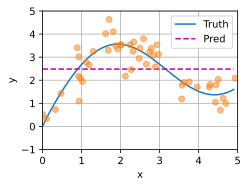

In [ ]:
y_hat = torch.repeat_interleave(y_train.mean(), n_test) # 训练集的 y 平均，复制50次
plot_kernel_reg(y_hat)

###  非参数注意力汇聚（核汇聚）

**1. 动机：平均汇聚的问题**

平均汇聚忽略了输入位置，因此 Nadaraya 和 Watson 提出按输入位置对输出加权，得到 Nadaraya-Watson 核回归。

**2. Nadaraya-Watson 核回归（式 10.2.3）**

$$f(x) = \sum_{i=1}^{n} \frac{K(x - x_i)}{\sum_{j=1}^{n} K(x - x_j)}\, y_i$$

K 叫作**核**（kernel），用来衡量 x 和 xᵢ 有多接近；分母负责归一化，让所有权重加起来等于 1。

**3. 改写成注意力汇聚（式 10.2.4）**

$$f(x) = \sum_{i=1}^{n} \alpha(x, x_i)\, y_i$$

输出是训练输出的加权平均，权重由查询与键的关系决定；对每个查询，所有权重非负且总和为 1。

| 角色 | 对应 |
| --- | --- |
| Query | 测试输入 x |
| Key | 训练输入 xᵢ |
| Value | 训练输出 yᵢ |
| 注意力权重 | α(x, xᵢ) |

**4. 代入高斯核（式 10.2.5 → 10.2.6）**

高斯核是 K 的一种具体选择：

$$K(u) = \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{u^2}{2}\right)$$

代入后得到整个预测值：

$$f(x) = \sum_{i=1}^{n} \mathrm{softmax}\left(-\frac{1}{2}(x - x_i)^2\right) y_i$$

其中 **softmax(...) 这一块就是注意力权重 α(x, xᵢ)**，再乘 yᵢ 求和，得到 f(x)。键越接近查询，分配到的注意力权重越大。

注意：softmax 不是只对一个数做（那样结果恒为 1），而是对所有 i 的分数组成的向量一起做，再取第 i 个元素。

**5. 为什么叫"非参数"**

这个模型没有可学习的参数，因此叫非参数注意力汇聚。

**6. 结果**

- **预测图**：与平均汇聚相比，预测线更平滑，也更贴近真实曲线。
- **热图**：行对应排序后的测试输入（查询），列对应排序后的训练输入（键）。两组输入都排过序，所以"查询-键"对越接近，注意力权重越高。

---

#### 补充

**1. 推导链与常数约掉**

| 步骤 | 公式 | 说明 |
| --- | --- | --- |
| ① 通用形式 | $\alpha(x, x_i) = \dfrac{K(x - x_i)}{\sum_j K(x - x_j)}$ | K 还没确定 |
| ② 选定 K | $K(u) = \dfrac{1}{\sqrt{2\pi}} e^{-u^2/2}$ | 选用高斯核 |
| ③ 代入 | $\alpha(x, x_i) = \dfrac{e^{-\frac{1}{2}(x-x_i)^2}}{\sum_j e^{-\frac{1}{2}(x-x_j)^2}}$ | 常数 1/√(2π) 约掉 |
| ④ 认出 softmax | $\alpha(x, x_i) = \mathrm{softmax}\left(-\frac{1}{2}(x-x_i)^2\right)$ | 形式正好是 eᵃⁱ / Σeᵃʲ |
| ⑤ 放回求和 | $f(x) = \sum_i \alpha(x, x_i)\, y_i$ | 得到式 10.2.6 |

分子分母的 1/√(2π) 互相抵消，所以**高斯核的归一化系数在这里不起作用**，代码里也就没有出现。

**2. 什么是"核"**

核就是**衡量两个点有多接近的函数**：距离为 0 时最大，距离越远越小。

| 核 | 形状 | 效果 |
| --- | --- | --- |
| 高斯核 | 钟形，平滑衰减 | 所有点都有权重，近的多、远的少 |
| 均匀核（盒子核） | 窗口内为 1，窗口外为 0 | 只对窗口内的点**等权平均** |
| Epanechnikov 核 | 抛物线形，超出范围为 0 | 介于两者之间 |

换一种核，就是换一种"相似度怎么算"。下一节"注意力评分函数"会把这个思路推广到向量。

**3. "非参数"不等于"没有可调的东西"**

教材的高斯核隐含了 **σ = 1**。完整的高斯核是：

$$K(u) = \exp\left(-\frac{u^2}{2\sigma^2}\right)$$

σ 叫作**带宽**，决定"看多远"：

- σ 大：窗口宽，参考的点多，曲线平滑，但会抹平细节。
- σ 小：窗口窄，只看最近的点，贴合细节，但容易被噪声带偏。

σ 是**超参数**，由人设定，不从数据中学习，所以模型仍叫"非参数"。


**4. "非参数"到底意味着什么**

| | 参数模型（如线性回归） | 非参数模型（本节） |
| --- | --- | --- |
| 训练后得到什么 | 一组参数（如 w、b） | 什么也不学 |
| 预测时需要什么 | 只要参数，训练数据可以丢掉 | **必须保留全部训练数据** |
| 预测怎么做 | 代入公式 | 每次和所有训练点现场算一遍 |

非参数模型相当于**把整个训练集当作模型本身**。代价是计算量：每个查询都要和所有训练点比一遍，权重矩阵大小为 n_test × n_train，数据量大时会很慢。

**5. 为什么预测曲线偏平，两端还有偏差**

- **偏平**：对这个问题来说，σ = 1 的窗口偏宽，距离 1 以上的点仍能拿到不少权重。附近起伏的点被一起平均，波峰被拉低、波谷被抬高。
- **两端偏差**（教材没提）：x 接近 0 或 5 时，训练点**只在一侧**。比如 x = 0 时邻居全在右边，加权平均会被右边的值拉过去。这叫**边界效应**，是核回归常见的问题。

**6. 热图怎么读**

- **横轴**是 50 个训练点（Key），**纵轴**是 50 个测试点（Query），都从小到大排好序。
- 每一**行**是一个测试点的权重分布，和为 1。
- **对角线附近最亮**：位置相近的查询和键距离最小，权重最大。

#### 总结
**流程理解**：输入一个测试点 $x$（Query），让它和训练集中的每个 $x_i$（Key）计算分数 $-\frac{1}{2}(x - x_i)^2$（等价于计算高斯核 $K(x - x_i)$）。再对所有分数做 $\mathrm{softmax}$，每个训练点就得到一个权重 $\alpha(x, x_i) \in (0, 1)$，并且 $\sum_i \alpha(x, x_i) = 1$。最后用这些权重对训练输出 $y_i$（Value）加权求和，得到预测值：

$$\hat{y} = \sum_{i=1}^{n} \alpha(x, x_i)\, y_i$$

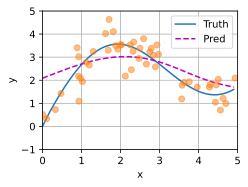

In [ ]:
# X_repeat的形状:(n_test,n_train),
# 测试集每个数复制50次，每50个数一行，和对应的五十个训练集输入做减法，最后softmax
X_repeat = x_test.repeat_interleave(n_train).reshape((-1, n_train))
# x_train包含着键。attention_weights的形状：(n_test,n_train),
# 每一行都包含着要在给定的每个查询的值（y_train）之间分配的注意力权重
attention_weights = nn.functional.softmax(-(X_repeat - x_train)**2 / 2, dim=1)
# y_hat的每个元素都是值的加权平均值，其中的权重是注意力权重
y_hat = torch.matmul(attention_weights, y_train)
plot_kernel_reg(y_hat)

**1. 非参数版本的不足**

非参数版本的窗口宽度是固定的（$\sigma = 1$）。对这个问题来说窗口偏宽，带来两个问题：

**（1）曲线偏平**：远处的点仍能分到可观的权重。以权重的相对大小为例：

| 与查询的距离 | 相对权重 $e^{-d^2/2}$ |
| --- | --- |
| $0$ | $1$ |
| $1$ | $\approx 0.61$ |
| $2$ | $\approx 0.14$ |

距离为 $1$ 的点，权重仍有最近点的六成左右。附近起伏的点被一起平均，波峰被拉低、波谷被抬高。

**（2）边界效应**：以测试输入 $x = 0.1$ 为例，真实值 $f(0.1) \approx 0.36$。离它最近的训练点（$x_i$ 接近 $0$）对应的 $y_i$ 较小，权重也最大，本该把预测拉向真实值。但问题在于：

- $x = 0.1$ 左边**没有训练点**，所有邻居都在右边；
- 右边的曲线快速上升，这些点的 $y_i$ 都明显大于 $f(0.1)$；
- 窗口又偏宽，右边稍远的点仍有不小的权重。

在区间中间，左右两侧的点一边偏大、一边偏小，加权后大致能相互抵消；而在边界处，**只有一侧的点，没有反方向的点来抵消**，加权平均被整体拉向右侧较大的 $y_i$，导致 $\hat{y}$ 明显高于真实值。$x$ 接近 $5$ 的右端同理。这就是核回归中常见的**边界效应**。

因此，自然的改进思路是：**让模型自己决定窗口该多宽**

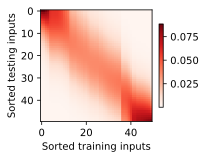

In [19]:
d2l.show_heatmaps(attention_weights.unsqueeze(0).unsqueeze(0),
                  xlabel='Sorted training inputs',
                  ylabel='Sorted testing inputs')

### 带参数注意力汇聚

与非参数版本相比只改了一处：**在距离上乘一个可学习的参数 $w$**。


#### 一、原理

**1. 为什么要加参数**

非参数版本的窗口宽度是固定的（$\sigma = 1$）。对这个问题来说窗口偏宽，预测曲线被平均得太平，波峰和波谷都不够。加参数的目的，是**让模型自己决定窗口该多宽**。

**2. 公式**

$$f(x) = \sum_{i=1}^{n} \mathrm{softmax}\left(-\frac{1}{2}\big((x - x_i)\,w\big)^2\right) y_i$$

| | 分数 | 可学习参数 |
| --- | --- | --- |
| 非参数 | $-\frac{1}{2}(x - x_i)^2$ | 无 |
| 带参数 | $-\frac{1}{2}\big((x - x_i)\,w\big)^2$ | $w$（只有这一个数） |

后面的步骤不变：$\mathrm{softmax}$ 得到权重 $\alpha(x, x_i)$，再对 $y_i$ 加权求和。

**3. $w$ 的作用：调节窗口宽窄**

$w$ 乘在距离 $x - x_i$ 上，相当于把距离放大或缩小：

- $w > 1$：距离被放大，稍远的点分数下降很快，权重集中在最近的几个点上，**窗口变窄**。
- $w < 1$：距离被缩小，远处的点也能分到不少权重，**窗口变宽**。
- $w = 1$：退化为非参数版本。

展开分数：

$$-\frac{1}{2}(x - x_i)^2 w^2$$

和带宽为 $\sigma$ 的高斯核 $-\dfrac{(x - x_i)^2}{2\sigma^2}$ 对比，可知：

$$w = \frac{1}{\sigma}$$

**让模型通过训练自己学出带宽**。

**例子**：查询 $x = 2.0$，训练点 $x_i = 1.0,\ 1.8,\ 2.1,\ 3.5$。

| $w$ | 权重 $\alpha(x, x_i)$ | 效果 |
| --- | --- | --- |
| $1$ | $0.21,\ 0.34,\ 0.34,\ 0.11$ | 四个点都参考 |
| $5$ | $\approx 0,\ 0.41,\ 0.59,\ \approx 0$ | 只看最近的两个点 |

**4. 训练 $w$**

训练时，**查询和键值对都来自训练集本身**：让每个训练点用**其他训练点**来预测自己，再和自己真实的 $y_i$ 比较，计算损失。

**排除自己**：如果第 $i$ 个点能看到自己，那么 $x_i - x_i = 0$，它的分数最高。只要把 $w$ 学得很大，权重就会全部压到自己身上，预测值正好等于 $y_i$，损失接近 $0$。但这样模型只是把训练数据背了下来，没有学到任何规律。所以每个训练样本**不与自身配对**：每个查询只配 $n - 1 = 49$ 个键值对。

**5. 预测**

训练完得到 $w$ 后，以测试点 $x$ 作为查询，用**全部** $50$ 个训练点作为键值对，按公式算出预测值 $\hat{y}$。预测时查询是新的点，不存在"看到自己"的问题，所以不需要排除。

**6. 结果**

带参数版本的拟合曲线在**注意力权重较大的区域更不平滑**。原因是学到的 $w$ 让窗口变窄，每个预测只依赖附近少数几个点。参与平均的点少了，**噪声就平均不掉**，曲线会跟着噪声抖动。热图上的对角亮带也会比非参数版本**窄得多**。

这是一个取舍：窗口宽，平滑但不够贴合；窗口窄，贴合但容易被噪声带偏。

#### 二、实现要点

**1. 批量矩阵乘法 bmm**

规则：

$$(b,\ n,\ m) \times (b,\ m,\ p) \rightarrow (b,\ n,\ p)$$

第一维 $b$ 是批量，**$b$ 对矩阵各自独立相乘**，每对是 $(n, m) \times (m, p)$。

**加权求和的套路**：把每组权重变成行向量 $(b, 1, m)$，每组值变成列向量 $(b, m, 1)$，相乘得到 $(b, 1, 1)$，也就是**每组各自做点积**。

例如 $2$ 组、每组 $10$ 个权重都是 $0.1$，值分别为 $0 \sim 9$ 和 $10 \sim 19$，结果分别是 $4.5$ 和 $14.5$（各组的平均值）。

**2. 模型的前向计算（以训练为例）**

| 步骤 | 形状 | 说明 |
| --- | --- | --- |
| 输入查询 $x_i$ | $(50,)$ | 训练输入 |
| 输入键、值 | $(50,\ 49)$ | 每行是去掉自己后的 $49$ 个点 |
| 查询复制成矩阵 | $(50,\ 49)$ | 每行是同一个查询 |
| 距离乘 $w$ | $(50,\ 49)$ | $(x - x_i)\,w$ |
| 打分 + $\mathrm{softmax}$ | $(50,\ 49)$ | 每行和为 $1$ |
| bmm 加权求和 | $(50,\ 1,\ 49) \times (50,\ 49,\ 1) \rightarrow (50,\ 1,\ 1)$ | 每行各自做点积 |
| 展平 | $(50,)$ | 每个查询一个预测值 |

- 整个模型**只有一个参数** $w$，随机初始化在 $[0, 1)$ 之间。
- 和非参数版相比，计算上**只多了乘 $w$ 这一步**。
- **为什么用 bmm 而不是普通矩阵乘法**：非参数版中所有查询共用同一组值，一次矩阵乘法就够了。这里训练时**每个查询有自己的一组值**（各自去掉的点不同），只能逐行各算各的。

**3. 构造训练用的键和值：用掩码去掉自己**

以 $4$ 个训练点 $[a, b, c, d]$ 为例。

① 把整个向量往下复制 $4$ 行：

$$\begin{bmatrix} a & b & c & d \\ a & b & c & d \\ a & b & c & d \\ a & b & c & d \end{bmatrix}$$

② 构造掩码 $1 - I$（$I$ 为单位矩阵），对角线为 $0$（False），其余为 $1$（True）：

$$1 - I = \begin{bmatrix} 0 & 1 & 1 & 1 \\ 1 & 0 & 1 & 1 \\ 1 & 1 & 0 & 1 \\ 1 & 1 & 1 & 0 \end{bmatrix}$$

③ 只保留 True 位置的元素，再整理成 $4$ 行：

$$\text{keys} = \begin{bmatrix} b & c & d \\ a & c & d \\ a & b & d \\ a & b & c \end{bmatrix}$$

第 $i$ 行就是第 $i$ 个查询能看到的键，**正好去掉了它自己**。值用同样方法从 $y$ 构造，与键一一对应。

真实规模下，键和值的形状都是 $(50,\ 49)$。

**4. 训练**

- **损失**：均方误差，先保留每个样本各自的损失（形状 $(50,)$），求和后再反向传播。
- **优化器**：随机梯度下降，学习率 $0.5$，更新的只有 $w$。
- **流程**：清空梯度 → 每个训练点用其余 $49$ 个点预测自己 → 和真实 $y_i$ 算损失 → 反向传播 → 更新 $w$。
- 只有一个参数，$5$ 个 epoch 损失就明显下降并趋于稳定。

**5. 预测**

| 变量 | 形状 | 说明 |
| --- | --- | --- |
| 键、值 | $(50,\ 50)$ | 每个测试点都能看到全部 $50$ 个训练点，每行相同 |
| 预测值 $\hat{y}$ | $(50,)$ | $50$ 个测试点的预测 |

- 预测时**不用掩码**，因为测试点和训练点不是同一批数据。
- 键和值仍然写成 $(\text{查询数},\ \text{键值对数})$ 的矩阵，是为了和训练时用同一套 bmm 计算。
- 画图前要切断梯度。

**6. 热图**

画的是最近一次前向计算（也就是预测时）的注意力权重，形状 $(50,\ 50)$：**行是测试点（Query），列是训练点（Key）**。读法和非参数版本一样，区别是**对角亮带明显变窄**：学到的 $w$ 让每个查询只关注离它最近的少数几个训练点。

#### 三、和非参数版本对比

| | 非参数（10.2.3） | 带参数（10.2.4） |
| --- | --- | --- |
| 分数 | $-\frac{1}{2}(x - x_i)^2$ | $-\frac{1}{2}\big((x - x_i)\,w\big)^2$ |
| 可学习参数 | 无 | $w$ |
| 是否训练 | 不需要 | 需要，每个点用其他点预测自己 |
| 加权求和 | 普通矩阵乘法（共用同一组值） | bmm（训练时每个查询有自己的一组值） |
| 热图亮带 | 宽 | 窄 |
| 预测曲线 | 平滑，偏平 | 更贴合，但在权重集中的区域不平滑 |

#### 四、一句话总结

> 带参数注意力汇聚只是在距离上乘了一个可学习的 $w$（即 $w = 1/\sigma$），让模型自己学出窗口宽度。训练时必须把每个点自己排除在外，否则模型会直接背答案。

In [ ]:
# bnm 是批量矩阵乘法
X = torch.ones((2, 1, 4)) # X 的每一行表示权重
Y = torch.ones((2, 4, 6)) # Y 的每一列表示k对应的值
torch.bmm(X, Y).shape

torch.Size([2, 1, 6])

定义模型

In [ ]:
class NWKernelRegression(nn.Module):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.w = nn.Parameter(torch.rand((1,), requires_grad=True)) # 要学习的参数，整个模型只有这一个参数

    def forward(self, queries, keys, values):
        # 一次查询 q，去找一行 k，计算权重后和 v 加权输出
        queries = queries.repeat_interleave(keys.shape[1]).reshape((-1, keys.shape[1])) # 查询复制为矩阵，保证 q 和 k 形状一致可以直接相减
        self.attention_weights = nn.functional.softmax(
            -((queries - keys) * self.w)**2 / 2, dim=1)
        # values的形状为(查询个数，“键－值”对个数)
        return torch.bmm(self.attention_weights.unsqueeze(1),
                         values.unsqueeze(-1)).reshape(-1)

假设我们有 3 个训练样本：

| 样本 | 输入 x | 输出 y |
|---|---|---|
| 1 | 1 | 2 |
| 2 | 2 | 4 |
| 3 | 3 | 8 |

训练时采用留一法（Leave-One-Out）：每个 Query 只能使用其他样本的 Key 和 Value，不能使用自身对应的键值对。


**Query：**

$$
Q=
\begin{bmatrix}
1\\
2\\
3
\end{bmatrix}
$$

**Key：**

$$
K=
\begin{bmatrix}
2&3\\
1&3\\
1&2
\end{bmatrix}
$$

**Value：**

$$
V=
\begin{bmatrix}
4&8\\
2&8\\
2&4
\end{bmatrix}
$$

其中每一行表示一个 Query 对应的 Key 和 Value。

假设当前可学习参数：

$$
\boxed{w=1}
$$

实际训练中，w 由随机初始化并通过梯度下降更新。这里固定为 1，仅用于展示一次前向传播。

---

#### 第一步：复制 Query


因为 `keys.shape[1] = 2`，所以每个 Query 需要重复 2 次。



得到Query：
$$
Q'=
\begin{bmatrix}
1&1\\
2&2\\
3&3
\end{bmatrix}
$$

这样 Query 和 Key 就可以逐元素相减。

计算：

$$
Q'-K=
\begin{bmatrix}
1&1\\
2&2\\
3&3
\end{bmatrix}
-
\begin{bmatrix}
2&3\\
1&3\\
1&2
\end{bmatrix}
$$

得到距离差矩阵：

$$
\boxed{
D=
\begin{bmatrix}
-1&-2\\
1&-1\\
2&1
\end{bmatrix}
}
$$


---

#### 第二步：计算注意力分数


计算公式：

$$
s_{ij}=-\frac{((q_i-k_{ij})w)^2}{2}
$$

由于假设 w=1，因此：

$$
S=-\frac{D^2}{2}
$$

代入距离差矩阵：

$$
D=
\begin{bmatrix}
-1&-2\\
1&-1\\
2&1
\end{bmatrix}
$$

首先逐元素平方：

$$
D^2=
\begin{bmatrix}
1&4\\
1&1\\
4&1
\end{bmatrix}
$$

再乘以 -1/2：

$$
\boxed{
S=
\begin{bmatrix}
-0.5&-2\\
-0.5&-0.5\\
-2&-0.5
\end{bmatrix}
}
$$

这是 Softmax 之前的注意力分数矩阵，形状为 (3,2)。

注意：分数越大，代表 Query 与 Key 越接近，后续得到的注意力权重也越高。

---

#### 第三步：Softmax 计算注意力权重


这里 `dim=1` 表示对矩阵的每一行分别进行 Softmax。

Softmax 公式：

$$
\alpha_{ij}
=
\frac{e^{s_{ij}}}
{\sum_t e^{s_{it}}}
$$

输入分数矩阵：

$$
S=
\begin{bmatrix}
-0.5&-2\\
-0.5&-0.5\\
-2&-0.5
\end{bmatrix}
$$

#####  最终注意力权重矩阵

将三行合并：

$$
\boxed{
A=
\begin{bmatrix}
0.817574&0.182426\\
0.500000&0.500000\\
0.182426&0.817574
\end{bmatrix}
}
$$

每一行的权重之和都等于 1。

---

#### 五、第四步：注意力权重与 Value 加权求和


$$
A=
\begin{bmatrix}
0.817574&0.182426\\
0.5&0.5\\
0.182426&0.817574
\end{bmatrix}
$$

Value：

$$
V=
\begin{bmatrix}
4&8\\
2&8\\
2&4
\end{bmatrix}
$$

注意：这里不是直接把两个 (3,2) 的矩阵相乘，而是让每一行的注意力权重与对应 Value 做一次矩阵乘法。

##### 1. 通过 unsqueeze 调整形状

原始权重：

$$
A.shape=(3,2)
$$


得到：

$$
(3,2)\rightarrow(3,1,2)
$$

原始 Value：

$$
V.shape=(3,2)
$$

得到：

$$
(3,2)\rightarrow(3,2,1)
$$

##### 2. 使用 bmm 批量矩阵乘法

$$
(3,1,2)\times(3,2,1)=(3,1,1)
$$

等价于分别执行三组矩阵乘法。


---

#### 最终结果汇总

| Query | Keys | Values | 注意力权重 | 预测输出 |
|---|---|---|---|---|
| 1 | [2,3] | [4,8] | [0.8176,0.1824] | 4.7297 |
| 2 | [1,3] | [2,8] | [0.5,0.5] | 5.0000 |
| 3 | [1,2] | [2,4] | [0.1824,0.8176] | 3.6351 |

最终预测：

$$
\boxed{
\hat Y=
\begin{bmatrix}
4.7297\\
5.0000\\
3.6351
\end{bmatrix}
}
$$

与真实标签：

$$
Y=
\begin{bmatrix}
2\\
4\\
8
\end{bmatrix}
$$

相比，目前存在较大的预测误差。

这是因为我们只是人为假设 w=1，还没有通过训练寻找更合适的参数；同时留一法和很少的训练样本也限制了预测能力。

后续训练阶段会计算预测损失，通过反向传播更新 w。

需要注意：即使经过训练，模型也不一定能够准确拟合所有样本。

---

#### 整个 forward 的张量形状变化

| 步骤 | 操作 | 输出形状 |
|---|---|---|
| 1 | 初始 queries | (3,) |
| 2 | repeat_interleave(2) | (6,) |
| 3 | reshape(-1,2) | (3,2) |
| 4 | queries - keys | (3,2) |
| 5 | 乘 w、平方、除以 -2 | (3,2) |
| 6 | Softmax(dim=1) | (3,2) |
| 7 | attention_weights.unsqueeze(1) | (3,1,2) |
| 8 | values.unsqueeze(-1) | (3,2,1) |
| 9 | torch.bmm(...) | (3,1,1) |
| 10 | reshape(-1) | (3,) |

#### 核心总结

带参数注意力汇聚的 forward 过程可以概括为：

1. **Query 复制**：将每个 Query 复制成与对应 Key 数量一致的形式。
2. **计算分数**：根据 Query-Key 距离和可学习参数 w 计算注意力分数。
3. **Softmax**：将每行分数转换成总和为 1 的注意力权重。
4. **加权求和**：利用 bmm，对每个 Query 对应的 Value 进行加权求和。
5. **返回预测**：将输出调整为一维张量。

数学表达：

$$
\boxed{
\hat y_i=
\sum_{j}
\frac{
\exp\left(-\frac{((q_i-k_{ij})w)^2}{2}\right)
}{
\sum_t\exp\left(-\frac{((q_i-k_{it})w)^2}{2}\right)
}
v_{ij}
}
$$

其中：

- q：当前查询。
- k：用于计算相似度的 Key。
- v：最终参与加权求和的 Value。
- w：整个模型唯一的可学习参数。
- Softmax：把注意力分数转化为归一化权重。
- bmm：批量完成多个 Query 的加权求和。



训练

In [ ]:
# X_tile的形状:(n_train，n_train)，即把整个张量沿第 0 维重复 3 次，沿第 1 维重复 1 次。
X_tile = x_train.repeat((n_train, 1))
# Y_tile的形状:(n_train，n_train)，即把整个张量沿第 0 维重复 3 次，沿第 1 维重复 1 次
Y_tile = y_train.repeat((n_train, 1))
# 对角线上的元素设置为 F 不参与训练，只有 T 参与训练
keys = X_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))
# 同理
values = Y_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))

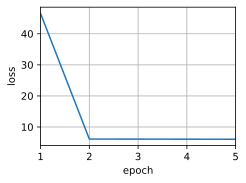

In [ ]:
net = NWKernelRegression()
loss = nn.MSELoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.5)
animator = d2l.Animator(xlabel='epoch', ylabel='loss', xlim=[1, 5])

for epoch in range(5):
    trainer.zero_grad()
    l = loss(net(x_train, keys, values), y_train)
    l.sum().backward()
    trainer.step()
    print(f'epoch {epoch + 1}, loss {float(l.sum()):.6f}')
    animator.add(epoch + 1, float(l.sum()))


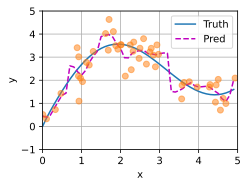

In [20]:
# keys的形状:(n_test，n_train)，每一行包含着相同的训练输入（例如，相同的键）
keys = x_train.repeat((n_test, 1))
# value的形状:(n_test，n_train)
values = y_train.repeat((n_test, 1))
y_hat = net(x_test, keys, values).unsqueeze(1).detach()
plot_kernel_reg(y_hat)

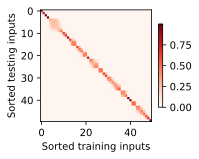

In [24]:
d2l.show_heatmaps(net.attention_weights.unsqueeze(0).unsqueeze(0),
                  xlabel='Sorted training inputs',
                  ylabel='Sorted testing inputs')